In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset = pd.read_csv("imdb_reviews.csv")
dataset.head()

,imdb_id,review title,review_rating,review
0,tt0369610,"Spielberg Magic, This Is Not. Still, a Visit t...",7.0,You may have heard some critics champion Juras...
1,tt0369610,"Not a patch on the original Jurassic Park, and...",7.0,The original Jurassic Park still is a personal...
2,tt0369610,Its a Jurassic World after all.,7.0,The 4th film in the Jurassic Park series and t...
3,tt0369610,Worthy Sequel To One Of The Greatest Films Eve...,NaN,Let's start this by stating how much of a die ...
4,tt0369610,Manages to somewhat return the Jurassic Park s...,6.0,Modernized and polished entry to the Jurassic ...


In [2]:
dataset.isnull().sum()

imdb_id            0
review title       0
review_rating    356
review             0
dtype: int64

In [3]:
dataset.review_rating.value_counts().sort_index()

review_rating
1.0       91
2.0       67
3.0      111
4.0      133
5.0      258
6.0     1293
7.0     1293
8.0      911
9.0      797
10.0     931
Name: count, dtype: int64

In [4]:
# Supprimer les avis sans note
print("Avant :", len(dataset))
dataset = dataset.dropna(subset=["review_rating"])
print("Après :", len(dataset))

Avant : 6241
Après : 5885


In [5]:
#Supprimer les doublons
print("Avant :", len(dataset))
dataset = dataset.drop_duplicates(subset=["review"])
print("Après :", len(dataset))

Avant : 5885
Après : 5861


In [6]:
SEUIL_NEG = 4   # note <= 4  -> negative
SEUIL_POS = 7   # note >= 7  -> positive

datasetNegative = dataset[dataset["review_rating"] <= SEUIL_NEG].copy()
datasetNegative["sentiment"] = "negative"

datasetPositive = dataset[dataset["review_rating"] >= SEUIL_POS].copy()
datasetPositive["sentiment"] = "positive"

print("Négatifs :", len(datasetNegative), "| Positifs :", len(datasetPositive))

Négatifs : 402 | Positifs : 3915


In [7]:
datasetPositive = datasetPositive.head(len(datasetNegative))

new_dataset = pd.concat([datasetNegative, datasetPositive])

In [8]:
new_dataset.to_csv("new_dataset_mini_projet.csv", index=False)

In [17]:
dataset = new_dataset.reset_index(drop=True)
dataset.sentiment.value_counts()

sentiment
negative    402
positive    402
Name: count, dtype: int64

In [19]:
# Mise en minuscules
dataset["review"] = dataset["review"].str.lower()
dataset["review"].head()

0    dinosaurs. amusement park. tourists. disaster....
1    plotmurphy is an american living in paris who ...
2    i have nothing against sex. i love it, i love ...
3    love is gaspar noe's latest film. it's essenti...
4    love, as it is titled, should be called bored ...
Name: review, dtype: str

In [21]:
import nltk
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
# Stemming
from nltk.stem import PorterStemmer
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.stem.porter import PorterStemmer
from nltk.stem.wordnet import WordNetLemmatizer

In [22]:
dataset["tokens"] = dataset["review"].apply(word_tokenize)
print("Liste des tokens :")
print(dataset["tokens"])

Liste des tokens :
0      [dinosaurs, ., amusement, park, ., tourists, ....
1      [plotmurphy, is, an, american, living, in, par...
2      [i, have, nothing, against, sex, ., i, love, i...
3      [love, is, gaspar, noe, 's, latest, film, ., i...
4      [love, ,, as, it, is, titled, ,, should, be, c...
                             ...                        
799    [unlike, fantasy, stories, like, lotr, ,, hobb...
800    [this, last, movie, had, a, sweeping, scope, ,...
801    [i, do, believe, a, good, movie, has, a, formu...
802    [personally, ,, i, actually, enjoy, the, hunge...
803    [sure, it, 's, still, got, some, of, the, date...
Name: tokens, Length: 804, dtype: object


In [23]:
stop_words = set(stopwords.words('english'))
print(f"Nombre de stopwords: {len(stop_words)}")
print(list(stop_words)[:20], "...")

Nombre de stopwords: 198
['re', 'our', 'how', 'by', 'some', 'will', "you'll", 'why', 'd', "mustn't", "i'd", 'itself', "he's", 'ours', 'where', 'down', 'wasn', "we've", "didn't", "wasn't"] ...


In [24]:
def filtrer(mots):
    return [mot for mot in mots if mot not in stop_words]

tokens_filtered = dataset["tokens"].apply(filtrer)
print("Tokens après suppression des stopwords :")
print(tokens_filtered)

Tokens après suppression des stopwords :
0      [dinosaurs, ., amusement, park, ., tourists, ....
1      [plotmurphy, american, living, paris, enters, ...
2      [nothing, sex, ., love, ,, love, watching, pai...
3      [love, gaspar, noe, 's, latest, film, ., 's, e...
4      [love, ,, titled, ,, called, bored, whiny, man...
                             ...                        
799    [unlike, fantasy, stories, like, lotr, ,, hobb...
800    [last, movie, sweeping, scope, ,, emotional, i...
801    [believe, good, movie, formula, -, starts, bac...
802    [personally, ,, actually, enjoy, hunger, games...
803    [sure, 's, still, got, dated, gooey-ness, orig...
Name: tokens, Length: 804, dtype: object


In [25]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

for mot in ["movies", "studies", "acting", "better", "was"]:
    print(f"{mot:10s} stem -> {stemmer.stem(mot):8s} // lemme -> {lemmatizer.lemmatize(mot)}")

movies     stem -> movi     // lemme -> movie
studies    stem -> studi    // lemme -> study
acting     stem -> act      // lemme -> acting
better     stem -> better   // lemme -> better
was        stem -> wa       // lemme -> wa


In [26]:
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

In [27]:
def clean_text(text):
    # Minuscules
    text = text.lower()

    # Supprimer URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Supprimer caractères spéciaux et chiffres
    text = re.sub(r'[^a-z\s]', '', text)

    # Tokenisation
    tokens = word_tokenize(text)

    # Supprimer stopwords et lemmatiser
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    # Reconstituer le texte
    return ' '.join(tokens)

# Créer la nouvelle colonne
dataset['cleaned_text'] = dataset['review'].apply(clean_text)

In [28]:
dataset

,imdb_id,review title,review_rating,review,sentiment,tokens,cleaned_text
0,tt0369610,The franchise has had a lobotomy,4.0,dinosaurs. amusement park. tourists. disaster....,negative,"[dinosaurs, ., amusement, park, ., tourists, ....",dinosaur amusement park tourist disasterjurass...
1,tt3774694,"Love: ""Art?"" No, no it really isn't.",2.0,plotmurphy is an american living in paris who ...,negative,"[plotmurphy, is, an, american, living, in, par...",plotmurphy american living paris enters highly...
2,tt3774694,Watch porn.,3.0,"i have nothing against sex. i love it, i love ...",negative,"[i, have, nothing, against, sex, ., i, love, i...",nothing sex love love watching painful sex hot...
3,tt3774694,Sex doesn't always sell,2.0,love is gaspar noe's latest film. it's essenti...,negative,"[love, is, gaspar, noe, 's, latest, film, ., i...",love gaspar no latest film essentially porn lo...
4,tt3774694,A long and tedious bore feast,1.0,"love, as it is titled, should be called bored ...",negative,"[love, ,, as, it, is, titled, ,, should, be, c...",love titled called bored whiny man child dirge...
...,...,...,...,...,...,...,...
799,tt1951266,Different from other Young Adult Genres but st...,7.0,"unlike fantasy stories like lotr, hobbits and ...",positive,"[unlike, fantasy, stories, like, lotr, ,, hobb...",unlike fantasy story like lotr hobbit harry po...
800,tt1951266,Amazing Ending to an Amazing Series,10.0,"this last movie had a sweeping scope, emotiona...",positive,"[this, last, movie, had, a, sweeping, scope, ,...",last movie sweeping scope emotional impact tru...
801,tt1951266,I wish it could achieve more,7.0,i do believe a good movie has a formula - it s...,positive,"[i, do, believe, a, good, movie, has, a, formu...",believe good movie formula start background bu...
802,tt1951266,"""The fire will burn forever."" - 7/10",7.0,"personally, i actually enjoy the hunger games ...",positive,"[personally, ,, i, actually, enjoy, the, hunge...",personally actually enjoy hunger game series f...


In [29]:
# Limites du prétraitement 
print(clean_text("This movie is not good"))
print(clean_text("This movie is good"))

movie good
movie good


### BoW et TF-IDF

In [32]:
from sklearn.feature_extraction.text import CountVectorizer

# Création du vectoriseur
bow = CountVectorizer()

# Vectorisation de la colonne cleaned_text
X_bow = bow.fit_transform(dataset["cleaned_text"])

print("Shape :", X_bow.shape)

Shape : (804, 15900)


In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Création du vectoriseur TF-IDF
tfidf = TfidfVectorizer()

# Vectorisation de la colonne cleaned_text
X_tfidf = tfidf.fit_transform(dataset["cleaned_text"])

print("Shape :", X_tfidf.shape)

Shape : (804, 15900)


In [37]:
from sklearn.model_selection import train_test_split
y = dataset["sentiment"]
X = X_tfidf

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=70,
    stratify=y
)

In [38]:
# Même découpage pour le Bag of Words
X_bow_train, X_bow_test, _, _ = train_test_split(
    X_bow,
    y,
    test_size=0.2,
    random_state=70,
    stratify=y
)

X_tfidf_train, X_tfidf_test = X_train, X_test

In [48]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [50]:
y_pred = model.predict(X_test)

In [52]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy :", accuracy)

print(classification_report(y_test, y_pred))

Accuracy : 0.8633540372670807
              precision    recall  f1-score   support

    negative       0.82      0.94      0.87        81
    positive       0.93      0.79      0.85        80

    accuracy                           0.86       161
   macro avg       0.87      0.86      0.86       161
weighted avg       0.87      0.86      0.86       161



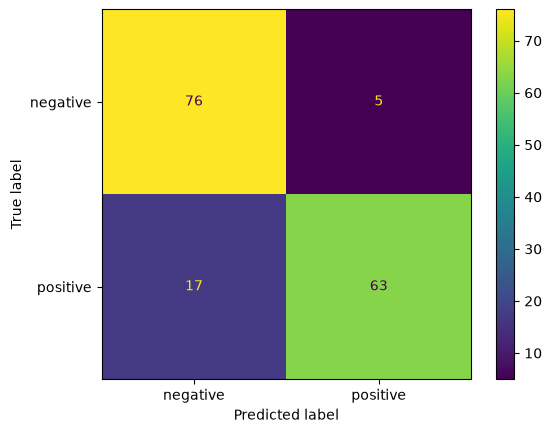

In [54]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.show()

In [56]:
from sklearn.metrics import f1_score

resultats = {}

def evaluer(nom, model, X_train, X_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    print(nom)
    print("Accuracy :", accuracy)
    print(classification_report(y_test, y_pred))

    resultats[nom] = {
        "Accuracy": accuracy,
        "F1": f1_score(y_test, y_pred, pos_label="positive")
    }
    return y_pred

In [58]:
y_pred_bow_lr = evaluer("BoW + Logistic Regression", LogisticRegression(max_iter=1000), X_bow_train, X_bow_test)

BoW + Logistic Regression
Accuracy : 0.8260869565217391
              precision    recall  f1-score   support

    negative       0.80      0.86      0.83        81
    positive       0.85      0.79      0.82        80

    accuracy                           0.83       161
   macro avg       0.83      0.83      0.83       161
weighted avg       0.83      0.83      0.83       161



In [60]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[321.,322.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.69,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U8](2,)","['negative','positive']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 15900)","[[0.06,0.06,0. ,...,0.08,0. ,0.09], [0. ,0.35,0. ,...,0. ,0.07,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 15900)","[[-9.78,-9.77,-9.83,...,-9.75,-9.83,-9.74], [-9.85,-9.55,-9.85,...,-9.85,-9.78,-9.85]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15900


In [62]:
y_pred_nb = nb_model.predict(X_test)

In [64]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Accuracy :", accuracy_nb)

print(classification_report(y_test, y_pred_nb))

Accuracy : 0.8633540372670807
              precision    recall  f1-score   support

    negative       0.95      0.77      0.85        81
    positive       0.80      0.96      0.88        80

    accuracy                           0.86       161
   macro avg       0.88      0.86      0.86       161
weighted avg       0.88      0.86      0.86       161



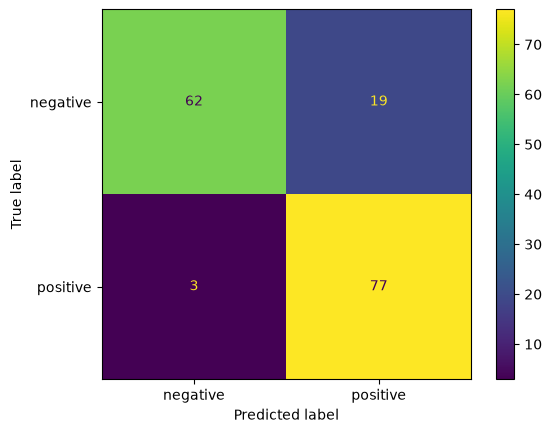

In [66]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb
)

plt.show()

In [68]:
y_pred_bow_nb = evaluer("BoW + Naive Bayes",
                        MultinomialNB(), X_bow_train, X_bow_test)

BoW + Naive Bayes
Accuracy : 0.906832298136646
              precision    recall  f1-score   support

    negative       0.89      0.93      0.91        81
    positive       0.92      0.89      0.90        80

    accuracy                           0.91       161
   macro avg       0.91      0.91      0.91       161
weighted avg       0.91      0.91      0.91       161



In [70]:
y_pred_tfidf_lr = evaluer("TF-IDF + Logistic Regression", LogisticRegression(max_iter=1000), 
                          X_tfidf_train,
                          X_tfidf_test)

TF-IDF + Logistic Regression
Accuracy : 0.8633540372670807
              precision    recall  f1-score   support

    negative       0.82      0.94      0.87        81
    positive       0.93      0.79      0.85        80

    accuracy                           0.86       161
   macro avg       0.87      0.86      0.86       161
weighted avg       0.87      0.86      0.86       161



In [72]:
y_pred_tfidf_nb = evaluer("TF-IDF + Naive Bayes", MultinomialNB(),
                          X_tfidf_train, X_tfidf_test)

TF-IDF + Naive Bayes
Accuracy : 0.8633540372670807
              precision    recall  f1-score   support

    negative       0.95      0.77      0.85        81
    positive       0.80      0.96      0.88        80

    accuracy                           0.86       161
   macro avg       0.88      0.86      0.86       161
weighted avg       0.88      0.86      0.86       161



              precision    recall  f1-score   support

    negative       0.95      0.77      0.85        81
    positive       0.80      0.96      0.88        80

    accuracy                           0.86       161
   macro avg       0.88      0.86      0.86       161
weighted avg       0.88      0.86      0.86       161



In [78]:
!pip install gensim

   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/24.4 MB ? eta -:--:--
    --------------------------------------- 0.5/24.4 MB 310.6 kB/s eta 0:01:17
   - -------------------------------------- 0.8/24.4 MB 472.3 kB/s eta 0:00:50
   - -------------------------------------- 0.8/24.4 MB 472.3 kB/s eta 0:00:50
   - -------------------------------------- 1.0/24.4 MB 585.1 kB/s eta 0:00:40
   - -------------------------------------- 1.0/24.4 MB 585.1 kB/s eta 0:00:40
   -- ------------------------------------- 1.3/24.4 MB 568.6 kB/s eta 0:00:41
   -- ------------------------------

In [80]:
from gensim.models import Word2Vec

# Chaque avis devient une liste de mots
corpus = [texte.split() for texte in dataset["cleaned_text"]]

# Skip-Gram (sg=1)
w2v_skip = Word2Vec(corpus, vector_size=100, window=5, min_count=2, sg=1, epochs=30)

# CBOW (sg=0)
w2v_cbow = Word2Vec(corpus, vector_size=100, window=5, min_count=2, sg=0, epochs=30)

print("Taille du vocabulaire Word2Vec :", len(w2v_skip.wv))

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Taille du vocabulaire Word2Vec : 7425


In [81]:
mots = ["good", "bad", "movie", "great", "love"]

for mot in mots:
    if mot in w2v_skip.wv:
        print("Skip-Gram", mot, "->", [m for m, s in w2v_skip.wv.most_similar(mot, topn=5)])
        print("CBOW     ", mot, "->", [m for m, s in w2v_cbow.wv.most_similar(mot, topn=5)])
        print()
    else:
        print(mot, "absent du vocabulaire\n")

Skip-Gram good -> ['torres', 'fernanda', 'statham', 'coda', 'transformer']
CBOW      good -> ['nice', 'decent', 'ritchies', 'solid', 'budget']

Skip-Gram bad -> ['ruined', 'nathanson', 'corey', 'guy', 'disposed']
CBOW      bad -> ['despicable', 'bunch', 'ritchies', 'ritchie', 'cooked']

Skip-Gram movie -> ['film', 'marketing', 'namely', 'liu', 'stink']
CBOW      movie -> ['mcu', 'expecting', 'film', 'surprised', 'flick']

Skip-Gram great -> ['movie', 'elevates', 'stink', 'film', 'really']
CBOW      great -> ['nice', 'solid', 'ensemble', 'superb', 'terrific']

Skip-Gram love -> ['interest', 'freddie', 'queen', 'realisation', 'poetic']
CBOW      love -> ['realisation', 'letter', 'interest', 'sex', 'poetic']

